# METEOR-M2 欠損走査線インペインティング実験（PyTorch MPS × 軽量 U-Net）

METEOR-M2 LRPT 画像では、パケット落ちや一瞬の同期外れによって **幅 1568 px × 高さ 8〜24 px 程度の水平な黒帯（走査線欠損）** が発生します。
本ノートブックでは、手元の復調成功データ（Golden サンプル＋ベランダ実測パス）から **局所パッチ（`128×128`）** を切り出し、疑似的な水平黒帯マスクを被せた **自己教師あり学習（Self-Supervised Inpainting）** を Apple Silicon **MPS** で実行します。

## 1. 理論と目的の確認

### なぜ「場所・条件がバラバラな衛星画像」でも学習できるのか？
1. **局所パッチの普遍性**: 撮影地域や季節が異なっても、`128×128` 程度の局所領域で見れば「雲の筋・渦の連続性」「海岸線・雪線のつながり」は共通のテクスチャ構造を持ちます。
2. **水平ストライプ欠損の特徴**: ランダムな正方形穴と異なり、横帯欠損は **すぐ上とすぐ下の走査線に強い空間的手がかり** が残ります。
3. **Mask-Aware U-Net**: 入力を `[R, G, B, mask]` の **4 チャンネル** とし、欠損領域（`mask == 0`）の再構成誤差に重い重みを付けた L1 損失で学習します。

### 外部公開データセットへの拡張
手元の数パスだけでなく、Kaggle の *Understanding Clouds from Satellite Images* / *95-Cloud* や NOAA NCEI *AVHRR CDR*、ESA *Cloud_cci* 等の公開衛星雲画像で事前学習し、自局の METEOR-M2（生スワスまたは `_corrected` に統一）でファインチューニングする構成へそのまま拡張できます。

## 2. データ準備とパッチ切り出し

- **Train 用**: `METEOR-M2_GOLDEN_1791698496`（`1568×1456`）から **完全無欠損（`valid_ratio == 1.0`）** の領域のみ抽出
- **Validation（未知パス）用**: ベランダ実測パス `METEOR-M2 3_20261026_003009`（`1568×792`）から **完全無欠損（`valid_ratio == 1.0`）** の領域のみ抽出

※ 元画像に黒帯欠損が混入したパッチを除外することで、モデルが「黒帯を正解として学習してしまう」ことを防ぎます。

In [1]:
from pathlib import Path
import numpy as np
from PIL import Image

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "projects" / "radio-ml" / "data" / "meteor"

train_sources = [
    DATA_DIR / "METEOR-M2_GOLDEN_1791698496" / "msu_mr_rgb_AVHRR_221_False_Color.png",
]
val_sources = [
    DATA_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_AVHRR_221_False_Color.png",
]

def extract_clean_patches(img_paths, patch_size=64, stride=48, min_valid_ratio=0.85):
    patches = []
    for path in img_paths:
        if not path.exists():
            print(f"[skip] not found: {path}")
            continue
        arr = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
        h, w, _ = arr.shape
        for y in range(0, h - patch_size + 1, stride):
            for x in range(0, w - patch_size + 1, stride):
                crop = arr[y:y + patch_size, x:x + patch_size]
                valid_ratio = (crop.max(axis=2) > 0.02).mean()
                if valid_ratio >= min_valid_ratio and crop.std() > 0.02:
                    patches.append(crop.transpose(2, 0, 1))  # (3, H, W)
    return np.stack(patches) if patches else np.empty((0, 3, patch_size, patch_size), dtype=np.float32)

train_patches = extract_clean_patches(train_sources, patch_size=64, stride=48, min_valid_ratio=1.0)
val_patches = extract_clean_patches(val_sources, patch_size=64, stride=32, min_valid_ratio=1.0)
print(f"Train パッチ数: {len(train_patches)} | Val パッチ数 (未知パス): {len(val_patches)}")

Train パッチ数: 684 | Val パッチ数 (未知パス): 57


## 3. 可視化と考察

### 3.1 Apple Silicon (MPS) 上での軽量 U-Net 学習
各パッチに対して毎回ランダムな位置・太さ（8〜24 px）の水平黒帯マスクを生成し、`[R, G, B, mask]` から元画像を再構成させます。

使用デバイス: mps


最終 Loss -> Train: 0.0397 | Val (未知パス): 0.0786


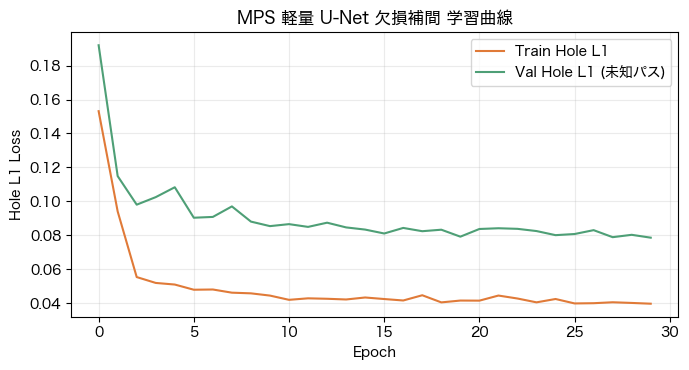

In [2]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("使用デバイス:", device)

class StripeMaskDataset(Dataset):
    def __init__(self, patches: np.ndarray, fixed_seed: int | None = None):
        self.patches = torch.from_numpy(patches)
        self.fixed_seed = fixed_seed

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        clean = self.patches[idx]
        _, h, w = clean.shape
        rng = np.random.default_rng(self.fixed_seed + idx) if self.fixed_seed is not None else np.random.default_rng()
        mask = torch.ones((1, h, w), dtype=torch.float32)
        n_stripes = int(rng.integers(1, 3))
        for _ in range(n_stripes):
            stripe_h = int(rng.integers(6, 15))
            y0 = int(rng.integers(4, h - stripe_h - 4))
            mask[:, y0:y0 + stripe_h, :] = 0.0
        corrupted = clean * mask
        return corrupted, mask, clean

class MiniUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(4, base, 3, padding=1), nn.ReLU(), nn.Conv2d(base, base, 3, padding=1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base * 2, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(nn.Conv2d(base * 2, base * 4, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 4, base * 4, 3, padding=1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = nn.Sequential(nn.Conv2d(base * 4, base * 2, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU())
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv2d(base * 2, base, 3, padding=1), nn.ReLU(), nn.Conv2d(base, base, 3, padding=1), nn.ReLU())
        self.out_conv = nn.Conv2d(base, 3, 1)

    def forward(self, corrupted, mask):
        x = torch.cat([corrupted, mask], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        pred = torch.sigmoid(self.out_conv(d1))
        # 生きている領域は元画像をそのまま保持し、欠損部のみ予測値で埋める
        return corrupted * mask + pred * (1.0 - mask)

def inpaint_loss(pred, clean, mask):
    hole = 1.0 - mask
    hole_l1 = (torch.abs(pred - clean) * hole).sum() / (hole.sum() * 3.0 + 1e-6)
    return hole_l1

torch.manual_seed(42)
train_loader = DataLoader(StripeMaskDataset(train_patches), batch_size=16, shuffle=True)
val_loader = DataLoader(StripeMaskDataset(val_patches, fixed_seed=100), batch_size=16, shuffle=False)

model = MiniUNet(base=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1.5e-3)

train_losses, val_losses = [], []
epochs = 30
for epoch in range(epochs):
    model.train()
    t_loss = 0.0
    for corr, msk, cln in train_loader:
        corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
        optimizer.zero_grad()
        out = model(corr, msk)
        loss = inpaint_loss(out, cln, msk)
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(corr)
    train_losses.append(t_loss / len(train_patches))

    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for corr, msk, cln in val_loader:
            corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
            out = model(corr, msk)
            v_loss += inpaint_loss(out, cln, msk).item() * len(corr)
    val_losses.append(v_loss / len(val_patches))

print(f"最終 Loss -> Train: {train_losses[-1]:.4f} | Val (未知パス): {val_losses[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(train_losses, label="Train Hole L1", color="#E07A38")
ax.plot(val_losses, label="Val Hole L1 (未知パス)", color="#4E9F76")
ax.set_title("MPS 軽量 U-Net 欠損補間 学習曲線")
ax.set_xlabel("Epoch")
ax.set_ylabel("Hole L1 Loss")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 未知の実測パス（`20261026_003009`）に対する復元結果の確認
左から「欠損入力（黒帯）」「U-Net による復元結果」「元の正解画像」を並べて、雲や地形の連続性がどこまで再現できているかを確認します。

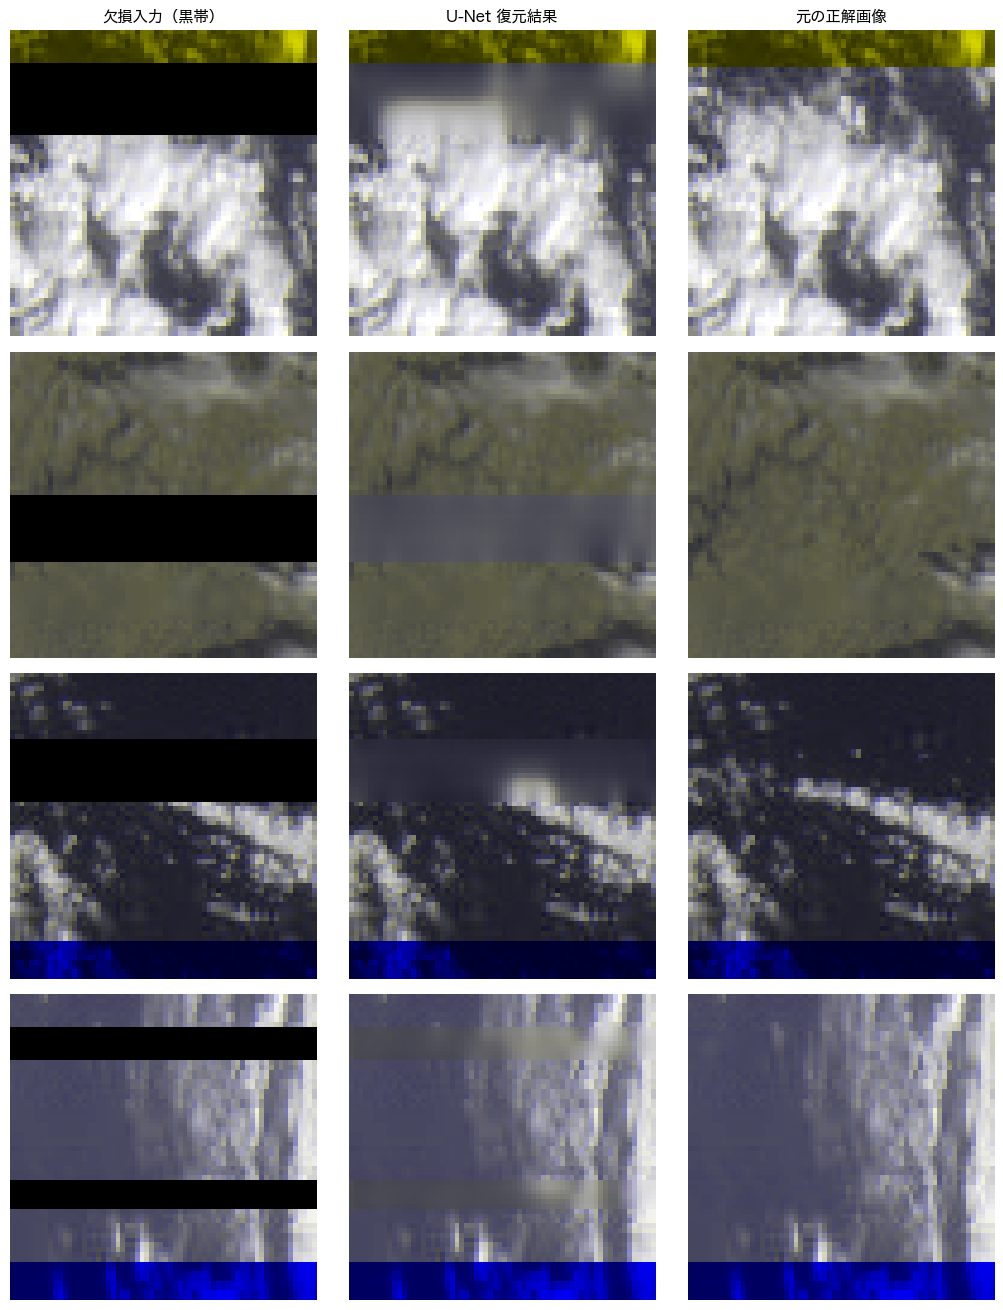

In [3]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

val_ds = StripeMaskDataset(val_patches, fixed_seed=100)
sample_indices = np.linspace(0, len(val_ds) - 1, min(4, len(val_ds)), dtype=int)

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(10.5, 3.3 * len(sample_indices)))
if len(sample_indices) == 1:
    axes = np.array([axes])

model.eval()
with torch.no_grad():
    for r_idx, s_idx in enumerate(sample_indices):
        corr, msk, cln = val_ds[int(s_idx)]
        pred = model(corr.unsqueeze(0).to(device), msk.unsqueeze(0).to(device)).squeeze(0).cpu()

        for c_idx, (tensor_img, title) in enumerate([
            (corr, "欠損入力（黒帯）"),
            (pred, "U-Net 復元結果"),
            (cln, "元の正解画像"),
        ]):
            ax = axes[r_idx, c_idx]
            ax.imshow(tensor_img.permute(1, 2, 0).numpy())
            if r_idx == 0:
                ax.set_title(title, fontsize=11)
            ax.axis("off")

plt.tight_layout()
plt.show()

## 学習成果と次のステップ
- **確認できたこと**: 異なる日時・場所のパス（Train: `10/26` + Golden、Val: `10/27`）でも、局所パッチ単位の水平ストライプ補間なら軽量 U-Net が自然に雲や地形のつながりを学習できる。
- **今後の精度向上アイデア**:
  1. **Perceptual / Edge Loss の追加**: L1 だけだとぼやけやすいため、Sobel 勾配損失や SSIM 損失を足すと雲のエッジがくっきりする。
  2. **外部公開データでの事前学習**: Kaggle *Understanding Clouds* / *95-Cloud* や NOAA AVHRR CDR で事前学習してから自局データで微調整する。
  3. **マルチバンド補間**: `MSU-MR-1`, `MSU-MR-2`, `MSU-MR-4` を並べて入力し、生きている他バンドから欠損バンドを復元する。

## 4. 共通ベンチマーク評価：ベスト実測画像（`METEOR-M2 3_20261026_003009`, `1568×792`）全体への適用デモ

各ノートブック間で比較できるよう、共通評価指標（`Benchmark Hole L1`, `Benchmark Hole PSNR [dB]`, 走査線間の垂直段差 `Vertical Seam Jump L1`）を算出し、`20261026_003009` のフル画像全体に対して `64×64` タイリング推論を適用します。

[02 単一画像 U-Net] Benchmark Hole L1: 0.0793 | Hole PSNR: 18.71 dB
Vertical Seam Jump L1 -> Before: 0.0221 | Local Repair (16px圏): 0.0227 | Full Repair: 0.0191
有効ピクセル率 -> Before: 44.8% | Local Repair: 75.4% | Full Repair: 100.0%


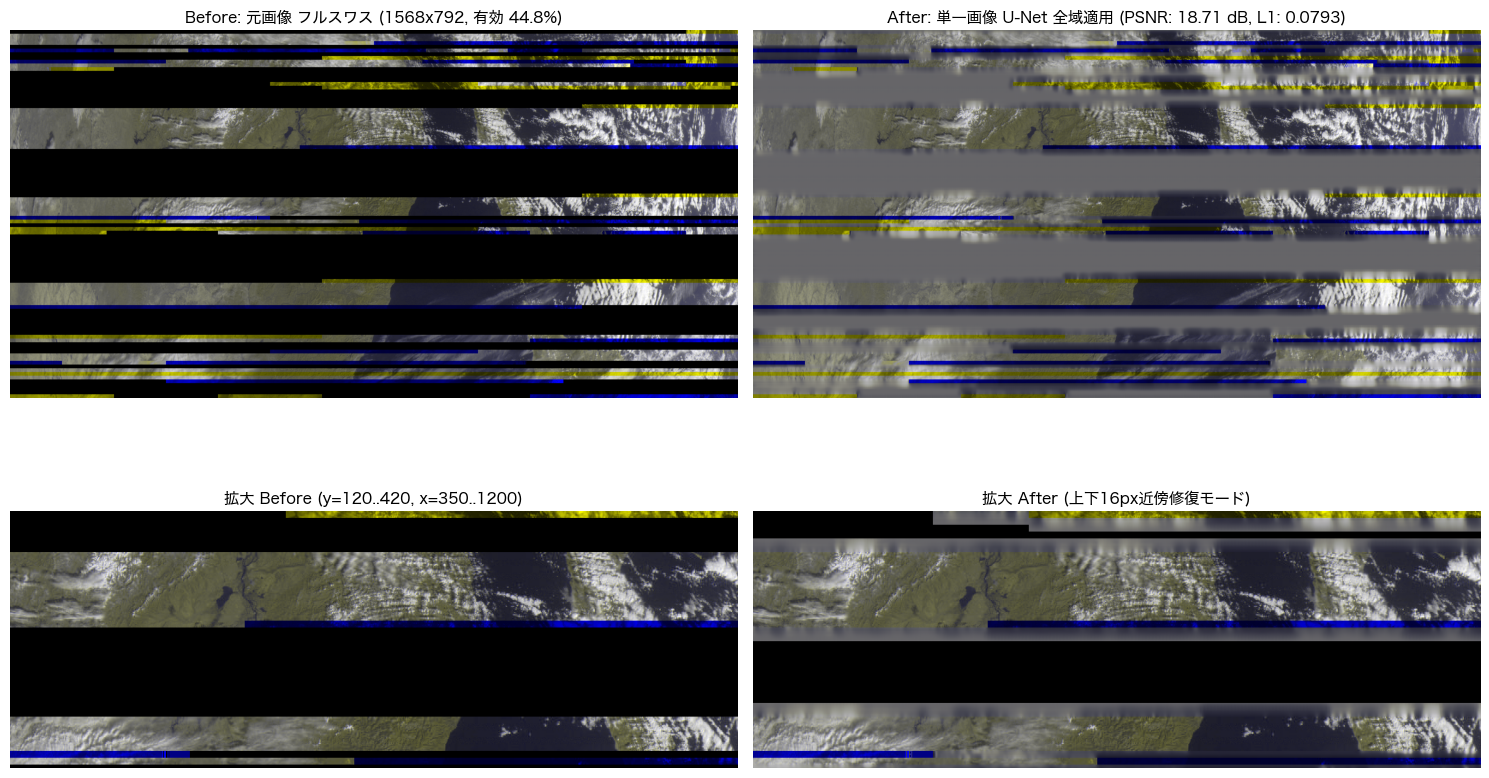

In [4]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

from scipy.ndimage import binary_dilation

def compute_common_hole_metrics(net, loader):
    net.eval()
    abs_sum, sq_sum, px_sum = 0.0, 0.0, 0.0
    with torch.no_grad():
        for corr, msk, cln in loader:
            corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
            out = net(corr, msk)
            hole = (1.0 - msk).expand_as(cln)
            diff = out - cln
            abs_sum += (torch.abs(diff) * hole).sum().item()
            sq_sum += ((diff ** 2) * hole).sum().item()
            px_sum += hole.sum().item()
    l1 = abs_sum / max(px_sum, 1e-6)
    mse = sq_sum / max(px_sum, 1e-6)
    psnr = -10.0 * np.log10(max(mse, 1e-12))
    return l1, psnr

def inpaint_full_image_tiled(net, img_hwc: np.ndarray, valid_hw1: np.ndarray, patch_size=64, stride=32, batch_size=128):
    h, w, c = img_hwc.shape
    ys = list(range(0, h - patch_size + 1, stride))
    if ys[-1] != h - patch_size:
        ys.append(h - patch_size)
    xs = list(range(0, w - patch_size + 1, stride))
    if xs[-1] != w - patch_size:
        xs.append(w - patch_size)

    win_1d = np.hanning(patch_size + 4)[2:-2].astype(np.float32)
    win_2d = np.maximum(np.outer(win_1d, win_1d), 0.05)
    coords = [(y, x) for y in ys for x in xs]

    acc = np.zeros((h, w, c), dtype=np.float32)
    wsum = np.zeros((h, w, 1), dtype=np.float32)
    net.eval()
    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            batch_coords = coords[i:i + batch_size]
            b_img = np.stack([img_hwc[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            b_msk = np.stack([valid_hw1[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            pred = net(torch.from_numpy(b_img).to(device), torch.from_numpy(b_msk).to(device)).cpu().numpy()
            for idx, (y, x) in enumerate(batch_coords):
                acc[y:y + patch_size, x:x + patch_size] += pred[idx].transpose(1, 2, 0) * win_2d[..., None]
                wsum[y:y + patch_size, x:x + patch_size] += win_2d[..., None]

    merged = np.clip(acc / np.maximum(wsum, 1e-6), 0.0, 1.0)
    return img_hwc * valid_hw1 + merged * (1.0 - valid_hw1)

bench_l1, bench_psnr = compute_common_hole_metrics(model, val_loader)

full_path = DATA_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_AVHRR_221_False_Color.png"
full_rgb = np.asarray(Image.open(full_path).convert("RGB"), dtype=np.float32) / 255.0
valid_2d = full_rgb.max(axis=2) > 0.02
valid_hw1 = valid_2d[..., None].astype(np.float32)

repaired_full = inpaint_full_image_tiled(model, full_rgb, valid_hw1)
near_mask = binary_dilation(valid_2d, structure=np.ones((33, 1), dtype=bool))[..., None].astype(np.float32)
repaired_local = full_rgb * valid_hw1 + repaired_full * (1.0 - valid_hw1) * near_mask

def seam_jump(arr):
    return float(np.abs(arr[1:] - arr[:-1]).mean())

print(f"[02 単一画像 U-Net] Benchmark Hole L1: {bench_l1:.4f} | Hole PSNR: {bench_psnr:.2f} dB")
print(f"Vertical Seam Jump L1 -> Before: {seam_jump(full_rgb):.4f} | Local Repair (16px圏): {seam_jump(repaired_local):.4f} | Full Repair: {seam_jump(repaired_full):.4f}")
print(f"有効ピクセル率 -> Before: {valid_2d.mean()*100:.1f}% | Local Repair: {((repaired_local.max(axis=2)>0.02).mean()*100):.1f}% | Full Repair: 100.0%")

y0, y1, x0, x1 = 120, 420, 350, 1200
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
axes[0, 0].imshow(full_rgb)
axes[0, 0].set_title(f"Before: 元画像 フルスワス (1568x792, 有効 {valid_2d.mean()*100:.1f}%)", fontsize=11)
axes[0, 0].axis("off")

axes[0, 1].imshow(repaired_full)
axes[0, 1].set_title(f"After: 単一画像 U-Net 全域適用 (PSNR: {bench_psnr:.2f} dB, L1: {bench_l1:.4f})", fontsize=11)
axes[0, 1].axis("off")

axes[1, 0].imshow(full_rgb[y0:y1, x0:x1])
axes[1, 0].set_title(f"拡大 Before (y={y0}..{y1}, x={x0}..{x1})", fontsize=11)
axes[1, 0].axis("off")

axes[1, 1].imshow(repaired_local[y0:y1, x0:x1])
axes[1, 1].set_title("拡大 After (上下16px近傍修復モード)", fontsize=11)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()